# Task 2: Customer Retention & Churn Analysis\nFuture Interns | Data Science & Analytics\n\nDataset is synthetic telecom-style demonstration data.

## 1. Upload the dataset

In [4]:
from google.colab import files
uploaded = files.upload()  # choose customer_churn.csv

Saving customer_churn.csv to customer_churn (1).csv


## 2. Import libraries and inspect

In [6]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
df = pd.read_csv('customer_churn.csv')
print(df.shape)
display(df.head())
df.info()

(7043, 15)


,CustomerID,Gender,SeniorCitizen,Partner,Dependents,Tenure,PhoneService,InternetService,Contract,PaperlessBilling,PaymentMethod,TechSupport,MonthlyCharges,TotalCharges,Churn
0,CUST-00001,Male,1,Yes,Yes,50,Yes,DSL,Month-to-month,No,Electronic check,No,25.32,1261.59,Yes
1,CUST-00002,Female,0,Yes,Yes,51,Yes,Fiber optic,One year,Yes,Mailed check,No,45.84,2358.17,No
2,CUST-00003,Male,0,Yes,Yes,16,Yes,DSL,Two year,Yes,Electronic check,Yes,86.60,1396.23,No
3,CUST-00004,Female,1,Yes,No,42,No,DSL,One year,No,Electronic check,No,38.31,1566.54,No
4,CUST-00005,Female,0,No,No,10,Yes,DSL,Two year,Yes,Electronic check,Yes,56.99,544.10,No


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   CustomerID        7043 non-null   object 
 1   Gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   Tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   InternetService   7043 non-null   object 
 8   Contract          7043 non-null   object 
 9   PaperlessBilling  7043 non-null   object 
 10  PaymentMethod     7029 non-null   object 
 11  TechSupport       7043 non-null   object 
 12  MonthlyCharges    7043 non-null   float64
 13  TotalCharges      7015 non-null   float64
 14  Churn             7043 non-null   object 
dtypes: float64(2), int64(2), object(11)
memory usage: 825.5+ KB


## 3. Clean data and create analysis fields

In [7]:
df['TotalCharges']=pd.to_numeric(df['TotalCharges'],errors='coerce')
df['TotalCharges']=df['TotalCharges'].fillna(df['TotalCharges'].median())
df['PaymentMethod']=df['PaymentMethod'].fillna('Unknown')
df=df.drop_duplicates(subset=['CustomerID'])
df['ChurnFlag']=df['Churn'].map({'Yes':1,'No':0})
df['TenureGroup']=pd.cut(df['Tenure'],[-1,6,12,24,48,72],labels=['0-6 months','7-12 months','13-24 months','25-48 months','49-72 months'])
df['MonthlyChargeBand']=pd.cut(df['MonthlyCharges'],[0,40,70,100,200],labels=['Low (≤40)','Medium (41-70)','High (71-100)','Very High (>100)'])
print(df.isna().sum())


CustomerID           0
Gender               0
SeniorCitizen        0
Partner              0
Dependents           0
Tenure               0
PhoneService         0
InternetService      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
TechSupport          0
MonthlyCharges       0
TotalCharges         0
Churn                0
ChurnFlag            0
TenureGroup          0
MonthlyChargeBand    0
dtype: int64


## 4. Calculate KPIs

In [8]:
customers=df.CustomerID.nunique()
churned=int(df.ChurnFlag.sum())
retained=customers-churned
display(pd.Series({'Customers':customers,'Churned':churned,'Retained':retained,'Churn rate (%)':churned/customers*100,'Retention rate (%)':retained/customers*100,'Average monthly charges':df.MonthlyCharges.mean(),'Average tenure':df.Tenure.mean()}).to_frame('Value').round(2))


,Value
Customers,7043.00
Churned,1813.00
Retained,5230.00
Churn rate (%),25.74
Retention rate (%),74.26
Average monthly charges,63.47
Average tenure,35.95


## Churn by Contract

,Contract,Customers,Churned,Churn_Rate
0,Month-to-month,3834,1402,36.567553
1,One year,1786,324,18.141097
2,Two year,1423,87,6.113844


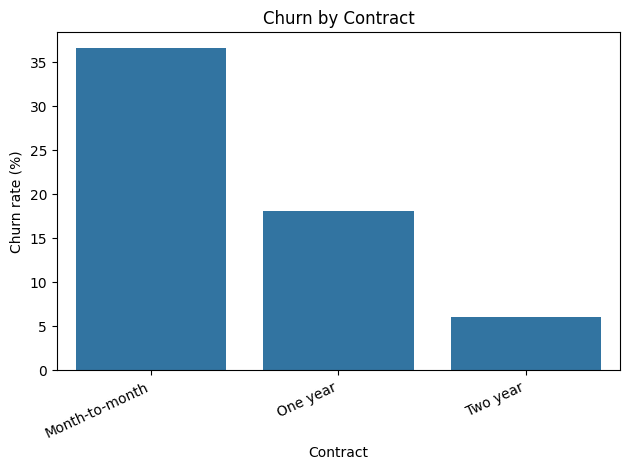

In [9]:
summary=df.groupby('Contract',observed=False).agg(Customers=('CustomerID','nunique'),Churned=('ChurnFlag','sum'),Churn_Rate=('ChurnFlag','mean')).reset_index()
summary['Churn_Rate']*=100
display(summary)
sns.barplot(data=summary,x='Contract',y='Churn_Rate')
plt.xticks(rotation=25,ha='right'); plt.ylabel('Churn rate (%)'); plt.title('Churn by Contract'); plt.tight_layout(); plt.show()


## Churn by Payment Method

,PaymentMethod,Customers,Churned,Churn_Rate
0,Bank transfer (automatic),1655,395,23.867069
1,Credit card (automatic),1602,379,23.657928
2,Electronic check,2396,704,29.382304
3,Mailed check,1376,331,24.055233
4,Unknown,14,4,28.571429


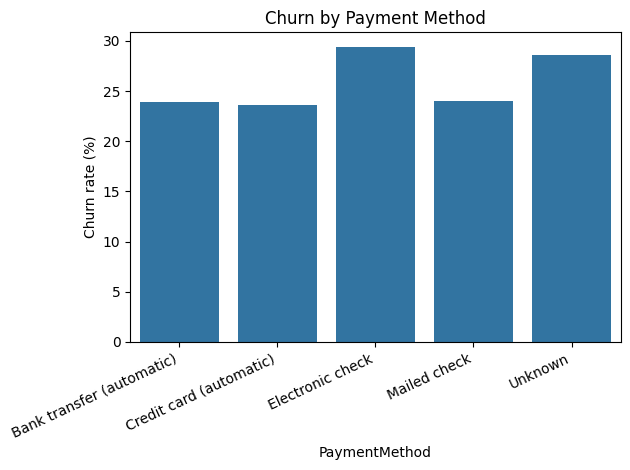

In [10]:
summary=df.groupby('PaymentMethod',observed=False).agg(Customers=('CustomerID','nunique'),Churned=('ChurnFlag','sum'),Churn_Rate=('ChurnFlag','mean')).reset_index()
summary['Churn_Rate']*=100
display(summary)
sns.barplot(data=summary,x='PaymentMethod',y='Churn_Rate')
plt.xticks(rotation=25,ha='right'); plt.ylabel('Churn rate (%)'); plt.title('Churn by Payment Method'); plt.tight_layout(); plt.show()


## Churn by Tenure Group

,TenureGroup,Customers,Churned,Churn_Rate
0,0-6 months,672,322,47.916667
1,7-12 months,595,204,34.285714
2,13-24 months,1184,260,21.959459
3,25-48 months,2272,481,21.170775
4,49-72 months,2320,546,23.534483


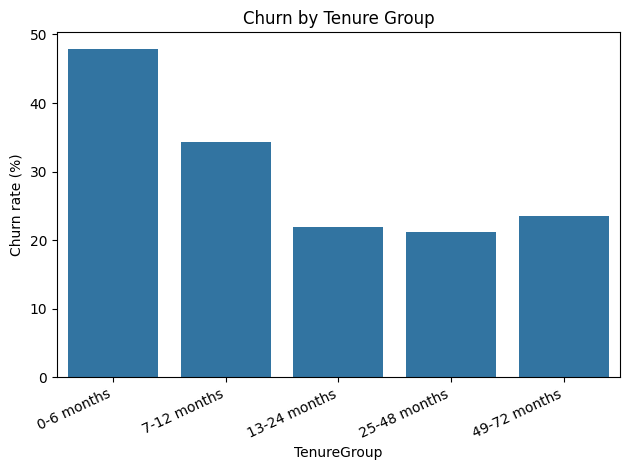

In [11]:
summary=df.groupby('TenureGroup',observed=False).agg(Customers=('CustomerID','nunique'),Churned=('ChurnFlag','sum'),Churn_Rate=('ChurnFlag','mean')).reset_index()
summary['Churn_Rate']*=100
display(summary)
sns.barplot(data=summary,x='TenureGroup',y='Churn_Rate')
plt.xticks(rotation=25,ha='right'); plt.ylabel('Churn rate (%)'); plt.title('Churn by Tenure Group'); plt.tight_layout(); plt.show()


## Churn by Monthly Charge Band

,MonthlyChargeBand,Customers,Churned,Churn_Rate
0,Low (≤40),1433,345,24.075366
1,Medium (41-70),2795,746,26.690519
2,High (71-100),2175,566,26.022989
3,Very High (>100),640,156,24.375000


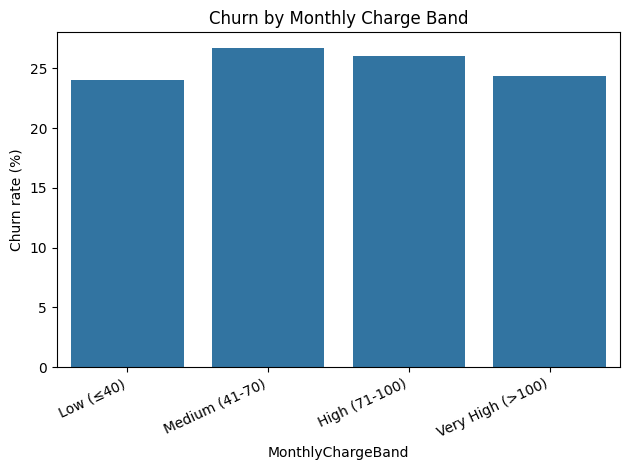

In [12]:
summary=df.groupby('MonthlyChargeBand',observed=False).agg(Customers=('CustomerID','nunique'),Churned=('ChurnFlag','sum'),Churn_Rate=('ChurnFlag','mean')).reset_index()
summary['Churn_Rate']*=100
display(summary)
sns.barplot(data=summary,x='MonthlyChargeBand',y='Churn_Rate')
plt.xticks(rotation=25,ha='right'); plt.ylabel('Churn rate (%)'); plt.title('Churn by Monthly Charge Band'); plt.tight_layout(); plt.show()


## Churn distribution and tenure comparison

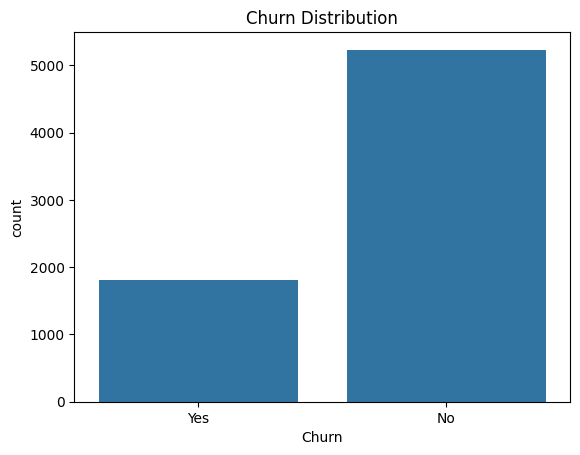

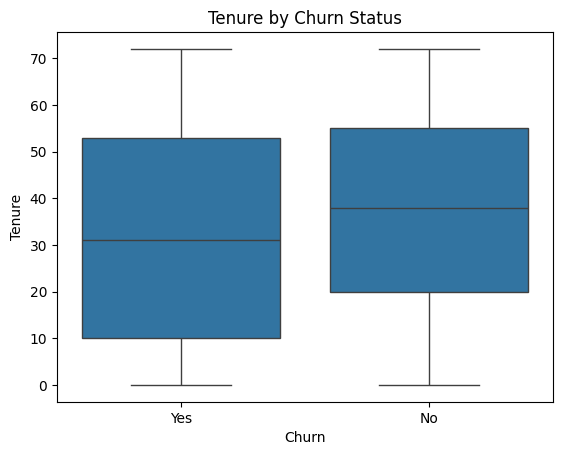

In [13]:
sns.countplot(data=df,x='Churn')
plt.title('Churn Distribution'); plt.show()
sns.boxplot(data=df,x='Churn',y='Tenure')
plt.title('Tenure by Churn Status'); plt.show()


## Export cleaned data

In [14]:
df.to_csv('cleaned_customer_churn.csv',index=False)\nfiles.download('cleaned_customer_churn.csv')\n

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Business interpretation\nIdentify groups with higher churn rates and compare the size of each group. Recommend targeted onboarding, billing support, and proactive retention actions. Associations do not prove causation. Results are synthetic.